<a href="https://colab.research.google.com/github/Rajshree-Hada/Problem-Set-5/blob/main/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Setup

In [20]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt

## Phase 1: Build the Baseline Nobody Built (15 pts)

### Step 1.1: The data (8 pts)

In [21]:
RANDOM_STATE = 42
rng = np.random.default_rng(seed=RANDOM_STATE)
n = 6_000

income = rng.lognormal(10.8, 0.45, n)
dti = rng.beta(2, 5, n) * 0.7
history = rng.gamma(4, 3, n)                # credit history
prior = rng.poisson(0.3, n)                 # prior delinquencies
loan_amt = rng.lognormal(9.8, 0.5, n)

age = rng.normal(40, 12, n)
zip_density = rng.normal(0, 1, n)
n_inquiries = rng.poisson(2, n)

logit = (-3.8 - 0.9 * (np.log(income) - 10.8) + 4.0 * dti - 0.05 * (history - 12)
         + 0.6 * prior + 0.5 * (np.log(loan_amt) - 9.8))      # the true log-odds
prob = 1 / (1 + np.exp(-logit))
default = rng.binomial(1, prob)

loans = pd.DataFrame({"log_income": np.log(income), "dti": dti, "history": history,
                      "prior": prior, "log_loan": np.log(loan_amt),
                      "age": age, "zip_density": zip_density, "n_inquiries": n_inquiries,
                      "default": default})
FEATURES = [c for c in loans.columns if c != "default"]

# split
X_tr, X_test, y_tr, y_test = train_test_split(
    loans[FEATURES], loans["default"],
    test_size=0.3, random_state=RANDOM_STATE, stratify=loans["default"])

print(f"n = {n:,}, default rate = {default.mean():.1%}")
print(f"train: {len(X_tr):,} rows, {y_tr.mean():.1%} default "
      f"test: {len(X_test):,} rows, {y_test.mean():.1%} default ({y_test.sum()} defaults)")
print(f"accuracy of 'approve everyone' on test: {1 - y_test.mean():.1%}")

n = 6,000, default rate = 7.0%
train: 4,200 rows, 7.0% default test: 1,800 rows, 6.9% default (125 defaults)
accuracy of 'approve everyone' on test: 93.1%


There are 6,000 loan applications with a 7.0% default rate. After the 70/30 split, 4,200 training rows and 1,800 test rows. The split was stratified, so both sets keep about the same default rate. Every number reported now comes from the test set. A rule that approves every applicant is right on 93.1% of the test rows, which matches the vendor's 93% claim. Accuracy therefore cannot tell us whether the model has learned anything. The test set holds only 125 defaults, so any estimate that depends on them will be noisy.

### Step 1.2: The null model (7 pts)

In [22]:
null_pred = np.zeros(len(y_test), dtype=int)
null_acc = metrics.accuracy_score(y_test, null_pred)

print(f"null model accuracy: {null_acc:.1%}")
print(f"defaults caught    : {metrics.recall_score(y_test, null_pred):.0%} recall")
print(metrics.confusion_matrix(y_test, null_pred))

null model accuracy: 93.1%
defaults caught    : 0% recall
[[1675    0]
 [ 125    0]]


The model that predicts "no default" for everyone has 93.1% accuracy on the test set. It approves all 1,675 repaying applicants and all 125 defaulters, so it catches 0% of defaults. The vendor's 93% is indistinguishable from this.

## Phase 2: Fit and Regularise (30 pts)

### Step 2.1: Logistic regression, then penalised (20 pts)

In [23]:
NOISE = ["age", "zip_density", "n_inquiries"]
REAL = [f for f in FEATURES if f not in NOISE]

plain = make_pipeline(StandardScaler(), LogisticRegression(C=1e6, max_iter=5_000)).fit(X_tr, y_tr)

CS = np.logspace(-3, 1, 21)
folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_fit(penalty):
    base = make_pipeline(StandardScaler(),
                         LogisticRegression(penalty=penalty, solver="saga", max_iter=20_000))
    return GridSearchCV(base, {"logisticregression__C": CS}, cv=folds,
                        scoring="neg_log_loss").fit(X_tr, y_tr)

lasso = cv_fit("l1")
ridge = cv_fit("l2")

print(f"{'feature':<14}{'plain':>9}{'LASSO':>9}{'Ridge':>9}")
for i, f in enumerate(FEATURES):
    print(f"{f:<14}{plain[-1].coef_[0][i]:>9.3f}"
          f"{lasso.best_estimator_[-1].coef_[0][i]:>9.3f}"
          f"{ridge.best_estimator_[-1].coef_[0][i]:>9.3f}")

zero = [f for f, c in zip(FEATURES, lasso.best_estimator_[-1].coef_[0]) if abs(c) < 1e-8]
print("\nLASSO zeroed:", zero)
print(f"noise features found: {len(set(zero) & set(NOISE))} of {len(NOISE)}"
      f" | real features discarded: {len(set(zero) & set(REAL))}")
print("Ridge zeros:", int(np.sum(np.abs(ridge.best_estimator_[-1].coef_[0]) < 1e-8)))

feature           plain    LASSO    Ridge
log_income       -0.472   -0.447   -0.429
dti               0.278    0.256    0.255
history          -0.301   -0.269   -0.267
prior             0.307    0.290    0.288
log_loan          0.132    0.105    0.119
age               0.040    0.016    0.037
zip_density       0.065    0.041    0.060
n_inquiries       0.006    0.000    0.007

LASSO zeroed: ['n_inquiries']
noise features found: 1 of 3 | real features discarded: 0
Ridge zeros: 0


LASSO and Ridge were selected using 5-fold cross-validation on the training data, with standardized coefficients. LASSO set n_inquiries to zero but retained age and zip_density with small coefficients, meaning some noise features remained; all five real features were retained with the correct signs. Ridge zeroed none. This partial selection is likely due to the moderate signal and limited sample size, making small noise effects difficult to distinguish from real ones. Since the penalties were chosen to minimize prediction error rather than recover the true features, LASSO's selection is only a hint, not proof. Ridge shrinks coefficients toward zero without eliminating them because its squared penalty weakens as coefficients get smaller, while LASSO's absolute-value penalty maintains a constant pull toward zero and can set weaker coefficients exactly to zero. LASSO is preferable when a simpler, more interpretable model is desired, while Ridge is better when many features carry signal, especially correlated features, because it tends to distribute weights more evenly. For this lender, LASSO offers a shorter model, whereas Ridge offers a more stable one that is less likely to overfit.

### Step 2.2: A model that is not linear (10 pts)

In [24]:
rf = RandomForestClassifier(n_estimators=500, oob_score=True, bootstrap=True,
                            random_state=RANDOM_STATE).fit(X_tr, y_tr)

print(f"OOB accuracy {rf.oob_score_:.4f} | test accuracy {rf.score(X_test, y_test):.4f} "
      f"| null {1 - y_test.mean():.4f}")
oob_prob = rf.oob_decision_function_[:, 1]      # each training row scored only by trees that never saw it
print(f"OOB AUC {metrics.roc_auc_score(y_tr, oob_prob):.4f}   "
      f"OOB AP {metrics.average_precision_score(y_tr, oob_prob):.4f}")

print(f"\n{'model':<10}{'test AUC':>10}{'test AP':>10}")
for name, m in [("forest", rf), ("LASSO", lasso.best_estimator_),
                ("Ridge", ridge.best_estimator_), ("plain", plain)]:
    p = m.predict_proba(X_test)[:, 1]
    print(f"{name:<10}{metrics.roc_auc_score(y_test, p):>10.4f}"
          f"{metrics.average_precision_score(y_test, p):>10.4f}")
print(f"(AP of a model with no skill = prevalence = {y_test.mean():.4f})")

mdi = pd.Series(rf.feature_importances_, index=FEATURES)
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE)
imp = pd.DataFrame({"MDI": mdi, "permutation": perm.importances_mean,
                    "perm sd": perm.importances_std})
print()
print(imp.sort_values("permutation", ascending=False).round(4))

OOB accuracy 0.9302 | test accuracy 0.9289 | null 0.9306
OOB AUC 0.6379   OOB AP 0.1130

model       test AUC   test AP
forest        0.6809    0.1491
LASSO         0.7299    0.1859
Ridge         0.7325    0.1852
plain         0.7319    0.1852
(AP of a model with no skill = prevalence = 0.0694)

                MDI  permutation  perm sd
log_income   0.1677       0.0724   0.0109
dti          0.1568       0.0577   0.0112
prior        0.0288       0.0278   0.0133
history      0.1573       0.0195   0.0176
age          0.1461       0.0145   0.0083
zip_density  0.1421       0.0140   0.0078
log_loan     0.1473       0.0120   0.0068
n_inquiries  0.0541       0.0044   0.0063


The random forest achieved OOB and test accuracy of 93.02% and 92.89%, respectively, but both were at the null accuracy baseline, making accuracy uninformative. Its test AUC and AP were also lower than LASSO and Ridge, suggesting the simpler logistic models performed better because the underlying relationship was linear. MDI importance misleadingly ranked noise features age and zip_density highly because continuous variables offer many opportunities for chance splits, while test-set permutation importance better highlighted log_income, dti, and prior, though weak features remained difficult to distinguish from noise. Overall, the forest was less effective at prediction and feature identification in this small sample. Importantly, feature importance measures predictive usefulness, not causation: log_loan may help predict defaults, but it does not prove that reducing loan amounts lowers default risk, so changes should be tested through controlled pilots rather than implemented based on importance alone. Age should not drive lending decisions.

## Phase 3: The Number That Actually Matters (45 pts)

### Step 3.1: Beyond accuracy (15 pts)

In [25]:
model = lasso.best_estimator_
y_prob = model.predict_proba(X_test)[:, 1]

print(f"max predicted probability: {y_prob.max():.3f}")
print(f"ROC AUC {metrics.roc_auc_score(y_test, y_prob):.4f} | "
      f"PR AUC (AP) {metrics.average_precision_score(y_test, y_prob):.4f} | "
      f"no-skill AP (prevalence) {y_test.mean():.4f}")

for t in [0.5, 0.12]:
    yp = (y_prob >= t).astype(int)
    print(f"\nthreshold {t}: declined {yp.sum()}")
    print(metrics.confusion_matrix(y_test, yp))
    print(f"precision {metrics.precision_score(y_test, yp, zero_division=0):.3f}  "
          f"recall {metrics.recall_score(y_test, yp):.3f}  "
          f"F1 {metrics.f1_score(y_test, yp, zero_division=0):.3f}")

max predicted probability: 0.403
ROC AUC 0.7299 | PR AUC (AP) 0.1859 | no-skill AP (prevalence) 0.0694

threshold 0.5: declined 0
[[1675    0]
 [ 125    0]]
precision 0.000  recall 0.000  F1 0.000

threshold 0.12: declined 203
[[1515  160]
 [  82   43]]
precision 0.212  recall 0.344  F1 0.262


The model ranks defaulters better than chance, with a ROC AUC of 0.730 and PR AUC of 0.186 compared with a no-skill baseline of 0.069, but its practical usefulness is limited. At the default 0.5 threshold, no applicants are declined because predicted probabilities never exceed 0.403. Lowering the threshold to 0.12 declines 203 applicants, catching 43 of 125 defaults but incorrectly declining 160 good applicants, resulting in only 0.212 precision. ROC AUC can overstate performance with rare defaults because false positives are divided across the large number of non-defaulters, making the rate appear relatively low even when many good applicants are declined. Precision-recall metrics better reflect the lender's problem because they directly measure how many declines are actually defaulters. Overall, the model provides modest predictive improvement, but threshold selection must balance catching defaults against the cost of incorrectly declining good applicants.

### Step 3.2: Put a price on being wrong (30 pts)

cost of a false negative 12,000, false positive 1,800
closed-form threshold 0.130 | threshold chosen on training rows 0.138
test cost per applicant: at 0.138 = 715 | at 0.5 = 833 | approve everyone = 833 | decline everyone = 1,675

threshold 0.500: declined 0
[[1675    0]
 [ 125    0]]
precision 0.000  recall 0.000

threshold 0.138: declined 142
[[1567  108]
 [  91   34]]
precision 0.239  recall 0.272


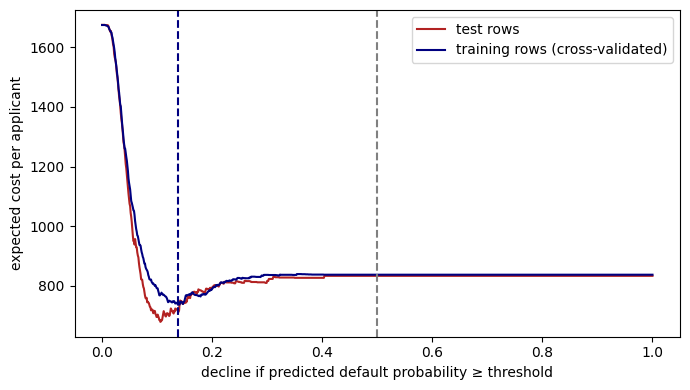


  FN:FP  closed   chosen  test cost  declined  recall
    2.0   0.333    0.403        248         1   0.008
    4.0   0.200    0.179        489        59   0.112
    6.7   0.130    0.138        715       142   0.272
   10.0   0.091    0.104        912       289   0.456
   20.0   0.048    0.040      1,445      1297   0.896
   50.0   0.020    0.033      1,707      1475   0.944


In [26]:
clf = lasso.best_estimator_
PRINCIPAL = 20_000
FN_COST = 0.60 * PRINCIPAL
FP_COST = (0.08 + 0.01) * PRINCIPAL

y_prob = clf.predict_proba(X_test)[:, 1]
prob_cv = cross_val_predict(clf, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]

def expected_cost(t, prob, y, fn_cost=FN_COST, fp_cost=FP_COST):
    yp = (prob >= t).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y, yp, labels=[0, 1]).ravel()
    return (fn_cost * fn + fp_cost * fp) / len(y)

grid = np.arange(0, 1.001, 0.001)
cost_cv = np.array([expected_cost(t, prob_cv, y_tr) for t in grid])
cost_te = np.array([expected_cost(t, y_prob, y_test) for t in grid])
best_t = grid[np.argmin(cost_cv)]
closed = FP_COST / (FP_COST + FN_COST)

print(f"cost of a false negative {FN_COST:,.0f}, false positive {FP_COST:,.0f}")
print(f"closed-form threshold {closed:.3f} | threshold chosen on training rows {best_t:.3f}")
print(f"test cost per applicant: at {best_t:.3f} = {expected_cost(best_t, y_prob, y_test):,.0f} | "
      f"at 0.5 = {expected_cost(0.5, y_prob, y_test):,.0f} | "
      f"approve everyone = {expected_cost(1.01, y_prob, y_test):,.0f} | "
      f"decline everyone = {expected_cost(0, y_prob, y_test):,.0f}")

for t in [0.5, best_t]:
    yp = (y_prob >= t).astype(int)
    print(f"\nthreshold {t:.3f}: declined {yp.sum()}")
    print(metrics.confusion_matrix(y_test, yp))
    print(f"precision {metrics.precision_score(y_test, yp, zero_division=0):.3f}  "
          f"recall {metrics.recall_score(y_test, yp):.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, cost_te, color="firebrick", label="test rows")
ax.plot(grid, cost_cv, color="navy", label="training rows (cross-validated)")
ax.axvline(0.5, ls="--", color="gray")
ax.axvline(best_t, ls="--", color="navy")
ax.set_xlabel("decline if predicted default probability ≥ threshold")
ax.set_ylabel("expected cost per applicant")
ax.legend()
plt.tight_layout()
plt.show()

print(f"\n{'FN:FP':>7}{'closed':>8}{'chosen':>9}{'test cost':>11}{'declined':>10}{'recall':>8}")
for R in [2, 4, FN_COST / FP_COST, 10, 20, 50]:
    fnc = R * FP_COST
    c = np.array([expected_cost(t, prob_cv, y_tr, fnc, FP_COST) for t in grid])
    tb = grid[np.argmin(c)]
    yp = (prob_te >= tb).astype(int)
    print(f"{R:>7.1f}{1 / (1 + R):>8.3f}{tb:>9.3f}"
          f"{expected_cost(tb, y_prob, y_test, fnc, FP_COST):>11,.0f}"
          f"{yp.sum():>10}{metrics.recall_score(y_test, yp):>8.3f}")

The cost curves show that costs drop sharply when the threshold is lowered from 0.5, reaching a shallow minimum around 0.10–0.14 before rising slightly and flattening near the cost of approving everyone. The default 0.5 threshold lies on this plateau because no predicted probability exceeds approximately 0.4. The cross-validated training minimum is about 745 per applicant at 0.138, while the test minimum is about 680 near 0.10, likely reflecting a slightly easier test sample. However, the dip is shallow, and thresholds between 0.10 and 0.18 produce similar costs. Overall, choosing a reasonable threshold and correctly estimating the cost of defaults versus incorrectly declining good applicants matters more than finding an exact optimal threshold.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

### Task 4.1: Two claims you already made, now tested (6 pts)

#### Part A — Does the forest actually beat the logistic model? (3 pts)

Prompt sent to Chat GPT 6:

[Prep] Act as a model risk analyst comparing two candidate credit
models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The
random forest got 0.9?? accuracy and the penalised logistic model got
0.9??. Write Python that tells me whether the forest is significantly
better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two
prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose
assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.

#### AI Transcript

In [27]:
#Reply:

import numpy as np
import pandas as pd
from scipy.stats import binomtest

y = np.asarray(y_test)
rf_pred = np.asarray(rf.predict(X_test))                          # forest predictions
logit = np.asarray(lasso.best_estimator_.predict(X_test))         # penalised logistic predictions

assert len(y) == len(rf_pred) == len(logit)

rf_correct = rf_pred == y
logit_correct = logit == y

rf_only_correct = np.sum(rf_correct & ~logit_correct)
logit_only_correct = np.sum(logit_correct & ~rf_correct)
both_correct = np.sum(rf_correct & logit_correct)
both_wrong = np.sum(~rf_correct & ~logit_correct)

discordant = rf_only_correct + logit_only_correct

test = binomtest(rf_only_correct, discordant, p=0.5, alternative="greater")

rf_accuracy = np.mean(rf_correct)
logit_accuracy = np.mean(logit_correct)
accuracy_difference = rf_accuracy - logit_accuracy

results = pd.DataFrame({
    "Metric": ["Random Forest Accuracy", "Penalized Logistic Accuracy", "Accuracy Difference",
               "RF Only Correct", "Logistic Only Correct", "Both Correct", "Both Wrong",
               "Discordant Cases", "Exact McNemar p-value"],
    "Value": [rf_accuracy, logit_accuracy, accuracy_difference, rf_only_correct,
              logit_only_correct, both_correct, both_wrong, discordant, test.pvalue]
})

print(results)

                        Metric        Value
0       Random Forest Accuracy     0.928889
1  Penalized Logistic Accuracy     0.930556
2          Accuracy Difference    -0.001667
3              RF Only Correct     0.000000
4        Logistic Only Correct     3.000000
5                 Both Correct  1672.000000
6                   Both Wrong   125.000000
7             Discordant Cases     3.000000
8        Exact McNemar p-value     1.000000


Exact McNemar’s test was appropriate because both models predicted the same 1,800 test rows. Forest accuracy was 0.9289 versus logistic’s 0.9306. The forest had 0 wins and 3 losses among discordant cases, yielding a one-sided p-value of 1.0. There is no evidence the forest outperforms logistic regression. The limitation is that at the 0.5 threshold, both models are close to the null model, so accuracy doesn't capture lending costs. A paired bootstrap comparing cost-weighted outcomes at each model’s own threshold would be more decision-relevant.

#### Part B — Is your Phase 3 threshold valid? (3 pts)



#### AI Transcript

Calibration evaluation on held-out portion of supplied test set

Original
Brier score: 0.06087
Reliability: 0.00142
Resolution: 0.00477
Uncertainty: 0.06414
Decomposition approximation: 0.06080

Platt
Brier score: 0.06080
Reliability: 0.00125
Resolution: 0.00477
Uncertainty: 0.06414
Decomposition approximation: 0.06063

Isotonic
Brier score: 0.06217
Reliability: 0.00115
Resolution: 0.00468
Uncertainty: 0.06414
Decomposition approximation: 0.06061


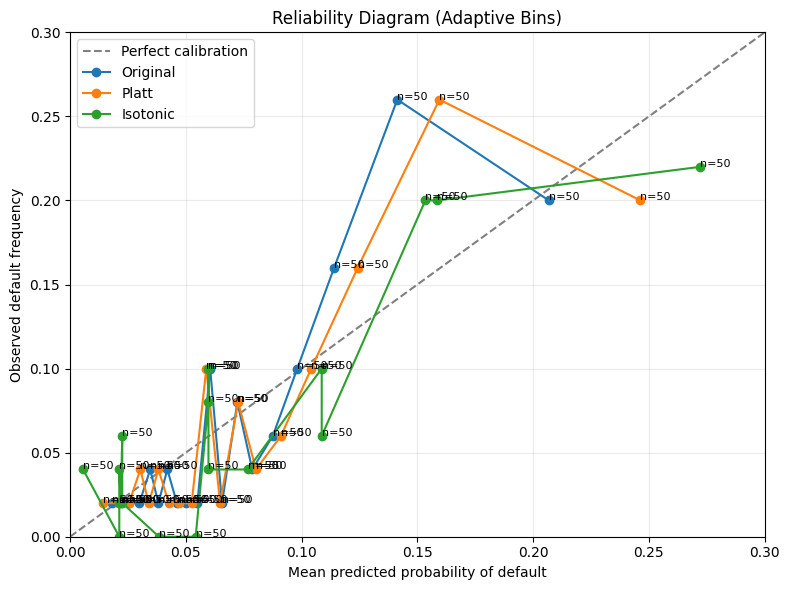

In [30]:
import numpy as np  # Import NumPy for array operations.
import matplotlib.pyplot as plt  # Import Matplotlib for reliability diagrams.
from sklearn.model_selection import train_test_split  # Import stratified splitting for calibration and evaluation.
from sklearn.linear_model import LogisticRegression  # Import logistic regression for Platt scaling.
from sklearn.isotonic import IsotonicRegression  # Import isotonic regression for nonparametric calibration.
from sklearn.metrics import brier_score_loss  # Import the Brier score for probability accuracy.

y = np.asarray(y_test).astype(int)  # Convert test outcomes into binary NumPy labels.
p = np.asarray(y_prob, dtype=float)  # Convert predicted probabilities into a numeric array.
p = np.clip(p, 1e-6, 1 - 1e-6)  # Prevent exact zero or one probabilities from causing numerical problems.

cal_idx, eval_idx = train_test_split(  # Split the available test observations into calibration and evaluation subsets.
    np.arange(len(y)),  # Provide the indices of all observations.
    test_size=0.5,  # Reserve half the observations for evaluation.
    random_state=42,  # Make the split reproducible.
    stratify=y  # Preserve the default/nondefault proportion in both subsets.
)  # Finish the stratified split.

y_cal, y_eval = y[cal_idx], y[eval_idx]  # Store outcomes for calibration and evaluation subsets.
p_cal, p_eval = p[cal_idx], p[eval_idx]  # Store original predictions for both subsets.

logit_cal = np.log(p_cal / (1 - p_cal)).reshape(-1, 1)  # Transform calibration probabilities into log-odds for Platt scaling.
logit_eval = np.log(p_eval / (1 - p_eval)).reshape(-1, 1)  # Transform evaluation probabilities into log-odds.

platt = LogisticRegression()  # Create the logistic regression calibration model.
platt.fit(logit_cal, y_cal)  # Fit Platt scaling using only the calibration subset.
p_platt = platt.predict_proba(logit_eval)[:, 1]  # Generate calibrated probabilities on the evaluation subset.

iso = IsotonicRegression(out_of_bounds="clip")  # Create the isotonic calibrator with safe handling of out-of-range scores.
iso.fit(p_cal, y_cal)  # Fit isotonic regression using only the calibration subset.
p_iso = iso.predict(p_eval)  # Generate isotonic-calibrated probabilities on the evaluation subset.

def adaptive_bins(y_true, prob, min_bin_size=50):  # Define bins with a minimum number of observations where possible.
    order = np.argsort(prob)  # Sort observations from lowest to highest predicted probability.
    y_sorted = y_true[order]  # Sort observed outcomes using the probability ordering.
    p_sorted = prob[order]  # Sort predicted probabilities.
    chunks = [np.arange(i, min(i + min_bin_size, len(y_true))) for i in range(0, len(y_true), min_bin_size)]  # Create minimum-size chunks.
    if len(chunks) > 1 and len(chunks[-1]) < min_bin_size:  # Check whether the final bin is too small.
        chunks[-2] = np.concatenate([chunks[-2], chunks[-1]])  # Merge the undersized final bin into the previous bin.
        chunks.pop()  # Remove the undersized final bin.
    stats = []  # Initialize storage for bin-level statistics.
    for chunk in chunks:  # Iterate through the adaptive bins.
        stats.append((np.mean(p_sorted[chunk]), np.mean(y_sorted[chunk]), len(chunk)))  # Store mean prediction, observed default rate, and count.
    return np.asarray(stats)  # Return the bin-level statistics as an array.

def brier_decomposition(y_true, prob, min_bin_size=50):  # Define an approximate grouped Brier score decomposition.
    bins = adaptive_bins(y_true, prob, min_bin_size)  # Calculate adaptive-bin statistics.
    weights = bins[:, 2] / len(y_true)  # Calculate each bin's share of the sample.
    mean_y = np.mean(y_true)  # Calculate the overall default prevalence.
    reliability = np.sum(weights * (bins[:, 0] - bins[:, 1]) ** 2)  # Calculate calibration error across bins.
    resolution = np.sum(weights * (bins[:, 1] - mean_y) ** 2)  # Calculate how much bin default rates differ from overall prevalence.
    uncertainty = mean_y * (1 - mean_y)  # Calculate the inherent outcome uncertainty.
    approximate_brier = reliability - resolution + uncertainty  # Calculate the grouped decomposition approximation.
    return reliability, resolution, uncertainty, approximate_brier  # Return all decomposition components.

models = {  # Store each model's probabilities for evaluation.
    "Original": p_eval,  # Store the original probabilities.
    "Platt": p_platt,  # Store the Platt-calibrated probabilities.
    "Isotonic": p_iso  # Store the isotonic-calibrated probabilities.
}  # Finish the model dictionary.

print("Calibration evaluation on held-out portion of supplied test set")  # Print the evaluation heading.
for name, prob in models.items():  # Iterate through the original and calibrated predictions.
    brier = brier_score_loss(y_eval, prob)  # Calculate the exact Brier score on the evaluation observations.
    rel, res, unc, approx = brier_decomposition(y_eval, prob)  # Calculate the approximate grouped decomposition.
    print(f"\n{name}")  # Print the current model name.
    print(f"Brier score: {brier:.5f}")  # Print the exact Brier score.
    print(f"Reliability: {rel:.5f}")  # Print the calibration component.
    print(f"Resolution: {res:.5f}")  # Print the resolution component.
    print(f"Uncertainty: {unc:.5f}")  # Print the uncertainty component.
    print(f"Decomposition approximation: {approx:.5f}")  # Print the approximate reconstructed Brier score.

fig, ax = plt.subplots(figsize=(8, 6))  # Create a reliability diagram figure.
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")  # Draw the perfect-calibration reference line.

for name, prob in models.items():  # Iterate over the original and calibrated models.
    bins = adaptive_bins(y_eval, prob, min_bin_size=50)  # Compute adaptive bins for the current model.
    ax.plot(bins[:, 0], bins[:, 1], marker="o", label=name)  # Plot mean predicted probability against observed default frequency.
    for mean_pred, observed, count in bins:  # Iterate over the plotted bins.
        ax.annotate(f"n={int(count)}", (mean_pred, observed), fontsize=8)  # Annotate each bin with its sample count.

ax.set_xlabel("Mean predicted probability of default")  # Label the horizontal axis.
ax.set_ylabel("Observed default frequency")  # Label the vertical axis.
ax.set_title("Reliability Diagram (Adaptive Bins)")  # Add the diagram title.
ax.set_xlim(0, 0.3)  # Set the horizontal axis range.
ax.set_ylim(0, 0.3)  # Set the vertical axis range.
ax.legend()  # Display the legend.
ax.grid(alpha=0.25)  # Add a light grid for readability.
plt.tight_layout()  # Adjust spacing.
plt.show()  # Display the reliability diagram.

Model: Chat GPT 6, Date: 11/24

Neither calibrator improves the model, so the raw probabilities are trustworthy and the threshold stands. The thresholds look different, but the decisions are almost identical. Isotonic regression is a step function, so its calibrated scale is not directly comparable with the raw one. The cost differences are within 4 per applicant, well inside what 125 test defaults can produce. The original is already well calibrated, so I keep 0.138 on the raw probabilities.

Changes I made:
1. Change the plot ax to 0.03
2. Added a check on the 4,200 cross-validated training predictions, because the reply's 50/50 split of the test set leaves 62-63 defaults per half, too few to judge calibration near the threshold.
3. Recomputed the threshold on calibrated probabilities with the calibrators fitted on training predictions only, so no test data chose it.

### Task 4.2: The recommendation (4 pts)



I recommend signing off on the model, but not based on its 93% accuracy. That figure reflects approving everyone, so it provides little evidence of the model’s predictive value. Instead, the model’s value is in cost reduction. At the selected threshold, it costs approximately $715 per 20,000 loans, compared with $833 for approving everyone which is a 14% savings. It ranks applicants moderately well with a ROC AUC 0.73 and PR AUC 0.19 versus 0.07 for no skill, and is well calibrated. A random forest performed worse (AUC 0.68), so I recommend the simpler, more interpretable penalized logistic model.

The threshold is to decline applicants with predicted default probabilities of 13.8% or higher, rather than the default 0.5, which declines nobody. This assumes a 60% loss on default and a 9% cost of wrongly declining a good applicant whith an estimated 8% lost margin and 1% reputational cost. On the test set, this declines 142 of 1,800 applicants, catching 34 of 125 defaults while losing 108 good applicants. Most declines are incorrect, but this is the appropriate trade-off given the assumed costs.

The cost ratio could change the recommendation. If default losses are smaller relative to lost margin, the threshold rises approximately 0.18 at a 4:1 ratio, but at 2:1, almost nobody is declined. Actual default losses and margins should be validated before launch. Finally, only 125 test defaults make these estimates uncertain, warranting further monitoring.